# 미션 7_반려동물 얼굴 객체 탐지

Oxford-IIIT Pet 사진에서 **고양이 · 강아지 얼굴의 위치(Bounding Box)와 종류** 탐지. COCO 사전학습 탐지 모델 2종의 정확도와 효율을 같은 조건에서 비교.

<img src="images/m7_map.png" alt="미션 7 학습 지도: 준비부터 마무리까지 6단계" width="726">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 박스 정답(XML)의 보유 현황 · 중복 · 크기 분포를 먼저 점검하고, 그 결과로 분할을 설계한다
2. 이미지와 박스를 **함께** 변환하는 증강을 만들고, 박스 수가 다른 이미지를 배치로 묶는다
3. 사전학습 탐지 모델의 분류 헤드를 새 클래스 수에 맞게 **교체**하고, 바뀌었는지 출력 채널로 확인한다
4. COCO 방식 mAP와 놓친 정답을 빼는 방식의 차이를 같은 예측으로 비교해 설명한다
5. 정확도 · 크기 · 속도를 함께 보고 모델을 고르고, 오류 사례에서 다음 개선점을 찾는다

## 🧭 활용처

- **반려동물 앱**: 사진 속 얼굴 위치로 자동 자르기 · 품종 분류 전처리
- **스마트 카메라**: 휴대폰 · 펫캠처럼 계산 자원이 작은 기기의 실시간 탐지 (가벼운 SSDLite 선택 근거)
- **탐지 모델 평가 일반**: 놓친 정답까지 반영하는 COCO mAP로 모델을 비교해야 하는 모든 탐지 과제

## 핵심 결과

- **최종 모델**: SSDLite320-MobileNetV3 (검증 기준 선택), 비교용 개발 평가셋 mAP@[.5:.95] **0.786** (사후 확인 성능, SSD300 0.779와 비슷)
- **효율**: 파라미터 **1/11**(2.2M vs 23.9M), 추론 속도 **2.4배**(244 vs 101장/초)
- **이미지 단위**: 551장 중 **540장(98.0%)** 얼굴 위치 · 종류 모두 정답
- **기본 예시 코드 수정**: 실제로 교체되지 않던 **분류 헤드**, 놓친 얼굴이 빠져 점수가 부풀던 **평가 방식**

**평가 기준**: COCO 방식 **mAP@[.5:.95]** (IoU 0.50~0.95 평균, 박스 위치 정밀도까지 반영). mAP@50 · mAP@75 · 클래스별 AP · 추론 속도도 함께 확인.

### 데이터 구성

- **출처**: Kaggle `zippyz/cats-and-dogs-breeds-classification-oxford-dataset` (Oxford-IIIT Pet)
- **이미지**: 37개 품종(고양이 12 · 강아지 25) 반려동물 사진 7,349장
- **분할 목록**: `trainval.txt` 3,680장 · `test.txt` 3,669장
- **박스 정답**: `xmls/*.xml`, PASCAL VOC 형식, 클래스(`cat` / `dog`)와 `xmin, ymin, xmax, ymax`
- **클래스**: 배경(0) · cat(1) · dog(2), 탐지 모델 규칙상 0번은 배경
- **주의** ⚠️: 공식 test에는 박스 정답 없음 → 1장에서 확인, 2장에서 분할 재설계
- **실행 환경**: 첫 실행 때 kagglehub가 데이터를 내려받아 캐시에 저장, 이후 실행은 캐시 사용

---
## 0. 준비

### 0-1. 환경 설정

**한글 요약**

데이터 처리 · 객체 탐지 · 평가 라이브러리를 불러오고, 한글 폰트 · 시드 · 클래스 이름 · 학습 장치 지정.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트 목록
2. **처리**: OpenMP 충돌 방지 → 라이브러리 불러오기 → 한글 폰트 지정
3. **저장**: `SEED` · `CLASSES` · `device`
4. **출력**: 학습 장치 이름

In [1]:
# 실행 환경
import os  # 환경 변수를 설정하기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # Windows Anaconda에서 numpy · PyTorch의 OpenMP 중복 로드 충돌을 막기 위해

# 라이브러리 불러오기
import copy  # 최고 성능 시점 가중치를 따로 보관하기 위해
import hashlib  # 파일 바이트 해시로 중복 이미지를 찾기 위해
import time  # 학습 · 추론 시간을 재기 위해
import xml.etree.ElementTree as ET  # 박스 정답 XML을 읽기 위해
from functools import partial  # 인자를 미리 채운 정규화 층을 만들기 위해
from pathlib import Path  # 운영체제와 상관없이 경로를 다루기 위해
import kagglehub  # Kaggle 데이터셋을 내려받기 위해
import matplotlib.patches as patches  # 이미지 위에 박스를 그리기 위해
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import numpy as np  # 배열 계산을 위해
import pandas as pd  # 목록 · 결과를 표로 다루기 위해
import torch  # 텐서 · GPU 연산을 위해
import torch.nn as nn  # SSDLite 헤드의 정규화 층을 만들기 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from PIL import Image  # 이미지 파일을 읽기 위해
from sklearn.metrics import average_precision_score  # 기본 예시 방식 AP를 재현하기 위해
from sklearn.model_selection import train_test_split  # 품종 비율을 유지해 나누기 위해
from torch.utils.data import DataLoader, Dataset  # 배치 단위로 데이터를 공급하기 위해
from torchmetrics.detection import MeanAveragePrecision  # 표준 COCO 방식 mAP를 계산하기 위해
from torchvision import tv_tensors  # 박스가 이미지와 함께 변환되도록
from torchvision.models.detection import (SSD300_VGG16_Weights, SSDLite320_MobileNet_V3_Large_Weights,
                                          ssd300_vgg16, ssdlite320_mobilenet_v3_large)  # COCO 사전학습 탐지 모델을 쓰기 위해
from torchvision.models.detection import _utils as det_utils  # 백본 특징맵 채널 수를 조회하기 위해
from torchvision.models.detection.ssd import SSDClassificationHead  # SSD 분류 헤드를 새로 만들기 위해
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead  # SSDLite 분류 헤드를 새로 만들기 위해
from torchvision.transforms import v2  # 이미지와 박스를 동시에 변환하기 위해

# 그래프 스타일
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed_fonts:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록

# 기본 설정
SEED = 42  # 분할 · 섞기 · 초기 가중치를 재현하기 위해
CLASSES = ["background", "cat", "dog"]  # 탐지 모델 규칙(0번 = 배경)에 맞추기 위해
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 있으면 학습을 빠르게 하기 위해
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")  # 학습 장치를 확인하기 위해

device: cuda | NVIDIA GeForce RTX 3060


**결과 해설**

```
device: cuda            : GPU로 학습
NVIDIA GeForce RTX 3060 : 학습 · 추론 시간은 이 GPU 기준
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| cuda.is_available()<br>cuda.get_device_name() | torch | GPU 사용 가능 여부<br>GPU 이름 | `torch.cuda.is_available()`<br>`torch.cuda.get_device_name(0)` |
| fontManager.ttflist<br>rcParams | matplotlib | 설치된 폰트 목록<br>그래프 전역 설정 | `font_manager.fontManager.ttflist`<br>`plt.rcParams["font.family"] = font` |
| environ.setdefault() | os | 없을 때만 환경 변수 설정 | `os.environ.setdefault(...)` |
| print() | Python 내장 함수 | 학습 장치 출력 | `print("device:", device, ...)` |
| import · from<br>조건 표현식<br>for · if · break | Python 기본 문법 | 라이브러리 불러오기<br>GPU 있으면 "cuda"<br>한글 폰트 탐색 후 중단 | `import torch.nn as nn`<br>`"cuda" if ... else "cpu"`<br>`for font in [...]:` |

---
## 1. 데이터 점검

### 1-1. 박스 정답과 중복 이미지

**한글 요약**

- 공식 분할 목록마다 **박스 정답(XML)이 있는 이미지 수** 확인 → 학습 · 평가에 쓸 범위 결정
- 확장자 분포로 **이미지가 아닌 파일** 확인
- MD5 해시로 **내용이 완전히 같은 중복 이미지**를 찾고 공식 목록과의 관계 확인

<img src="images/m7_data.png" alt="박스 정답이 있는 3,671장과 70 : 15 : 15 분할" width="837">

**실행 흐름**

1. **입력**: kagglehub 캐시의 이미지 폴더 · `trainval.txt` · `test.txt` · `xmls/`
2. **처리**: 분할별 XML 보유 수 집계 → 확장자 분포 → 이미지별 MD5 해시 → 중복 그룹 집계
3. **저장**: `trainval` · `test_official` · `xml_names` · `hashes`
4. **출력**: 정답 보유 표 · 확장자 분포 · 중복 그룹 수

In [2]:
# 데이터 경로
root = Path(kagglehub.dataset_download("zippyz/cats-and-dogs-breeds-classification-oxford-dataset"))  # 실행 환경마다 다른 캐시 경로를 받기 위해
img_dir = root / "images" / "images"  # 이미지 폴더를 한 번만 정의하기 위해
ann_dir = root / "annotations" / "annotations"  # 분할 목록 · XML 폴더를 한 번만 정의하기 위해

# 공식 분할 목록
cols = ["image", "class_id", "species", "breed_id"]  # 헤더 없는 목록에 열 이름을 붙이기 위해 (이름, 품종 번호, 종 1 cat · 2 dog, 품종 내 번호)
trainval = pd.read_csv(ann_dir / "trainval.txt", sep=r"\s+", header=None, names=cols)  # 공백 구분 목록을 표로 읽기 위해
test_official = pd.read_csv(ann_dir / "test.txt", sep=r"\s+", header=None, names=cols)  # 공식 test도 같은 형식으로 읽기 위해

# 분할별 박스 정답 보유
xml_names = {p.stem for p in (ann_dir / "xmls").glob("*.xml")}  # 정답 유무를 빠르게 확인하기 위해 집합으로 저장
audit = pd.DataFrame({
    "이미지 수": [len(trainval), len(test_official)],  # 목록 규모를 비교하기 위해
    "XML 있음": [trainval["image"].isin(xml_names).sum(), test_official["image"].isin(xml_names).sum()],  # 정량 평가가 가능한 범위를 알기 위해
}, index=["공식 trainval", "공식 test"])  # 행 이름으로 분할을 구분하기 위해
display(audit)  # 분할 × 정답 보유 표를 보기 위해

# 확장자 분포
files = sorted(img_dir.iterdir())  # 실행마다 같은 순서로 처리하기 위해 정렬
print("확장자 분포:", pd.Series([p.suffix.lower() for p in files]).value_counts().to_dict())  # 이미지가 아닌 파일을 찾기 위해

# 완전 중복 이미지
listed = set(trainval["image"]) | set(test_official["image"])  # 공식 목록 포함 여부를 확인하기 위해
hash_rows = []  # 이미지별 해시를 모으기 위해
for p in files:
    if p.suffix == ".jpg":  # 이미지 파일만 비교하기 위해
        hash_rows.append({"image": p.stem, "md5": hashlib.md5(p.read_bytes()).hexdigest(), "in_list": p.stem in listed})  # 내용이 같은 파일을 찾기 위해 해시 계산
hashes = pd.DataFrame(hash_rows)  # 해시를 기준으로 묶기 위해 표로 변환
dup = hashes[hashes.duplicated("md5", keep=False)]  # 해시가 같은 모든 행을 보기 위해
listed_per_group = dup.groupby("md5")["in_list"].sum()  # 중복이 분할 간 누수를 만드는지 보기 위해
print(f"중복 그룹 {dup['md5'].nunique()}개 · {len(dup)}장 · 그룹당 공식 목록 이미지 수: {listed_per_group.value_counts().to_dict()}")  # 중복 규모 · 구조를 확인하기 위해

,이미지 수,XML 있음
공식 trainval,3680,3671
공식 test,3669,0


확장자 분포: {'.jpg': 7390, '.mat': 3}


중복 그룹 29개 · 59장 · 그룹당 공식 목록 이미지 수: {1: 29}


**결과 해설**

```
공식 test XML 0장         : 3,669장 모두 박스 정답 없음 → 정량 평가 불가, 4-4 눈 확인에만 사용
공식 trainval XML 3,671장 : 3,680장 중 9장 정답 누락 → 정답 있는 3,671장으로 학습 · 검증 · 평가
.mat 3개                  : 이미지가 아닌 파일 → 사용하지 않음
중복 29그룹 · 59장        : 모든 그룹이 공식 목록 1장 + 목록 밖 복사본 → 공식 목록만 쓰면 누수 없음
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dataset_download() | kagglehub | 내려받기 · 캐시 경로 반환 | `kagglehub.dataset_download(...)` |
| Path · / 연산<br>glob() · iterdir()<br>stem · suffix · read_bytes() | pathlib | 경로 객체 · 결합<br>패턴 파일 · 폴더 전체<br>이름 · 확장자 · 바이트 | `root / "images"`<br>`.glob("*.xml")` · `img_dir.iterdir()`<br>`p.stem` · `p.read_bytes()` |
| md5() · hexdigest() | hashlib | 내용 해시 · 16진수 | `hashlib.md5(...).hexdigest()` |
| read_csv() · DataFrame() · Series()<br>isin() · value_counts()<br>duplicated() · groupby() | pandas | 목록 읽기 · 표 · 시리즈<br>포함 여부 · 개수<br>중복 표시 · 그룹 집계 | `pd.read_csv(..., sep=r"\s+")`<br>`.isin(xml_names)` · `.value_counts()`<br>`.duplicated("md5", keep=False)` |
| display() | IPython.display | 셀 중간 표 출력 | `display(audit)` |
| sorted() · len() · set() | Python 내장 함수 | 순서 고정 · 개수 · 집합 | `sorted(img_dir.iterdir())` |
| { ... for ... }<br>\| 연산<br>f-문자열 | Python 기본 문법 | XML 이름 집합<br>두 집합 합치기<br>결과 문장 | `{p.stem for p in ...}`<br><code>set(...) &#124; set(...)</code><br>`f"중복 그룹 ..."` |

### 1-2. 박스 정답 분포

**한글 요약**

- XML에서 이미지 크기 · 클래스 · 박스 좌표를 읽는 함수로 정답 있는 3,671장 파싱
- 이미지당 · 클래스별 박스 수 집계, 박스가 **무엇을 가리키는지** 예시 3장으로 확인
- 이미지 대비 박스 너비 · 높이 비율로 **크기 분포** 시각화

**실행 흐름**

1. **입력**: `xml_names`에 있는 trainval 이미지의 XML
2. **처리**: XML 파싱 → 박스별 상대 크기 계산 → 이미지당 · 클래스별 박스 수 집계
3. **저장**: `data` · `parsed` · `boxes`
4. **출력**: 박스 규모 · 클래스 분포, 예시 3장 + 크기 산점도

이미지 3,671장 · 박스 3,672개 · 이미지당 박스 수: {1: 3670, 2: 1}
클래스별 박스: {'dog': 2490, 'cat': 1182}


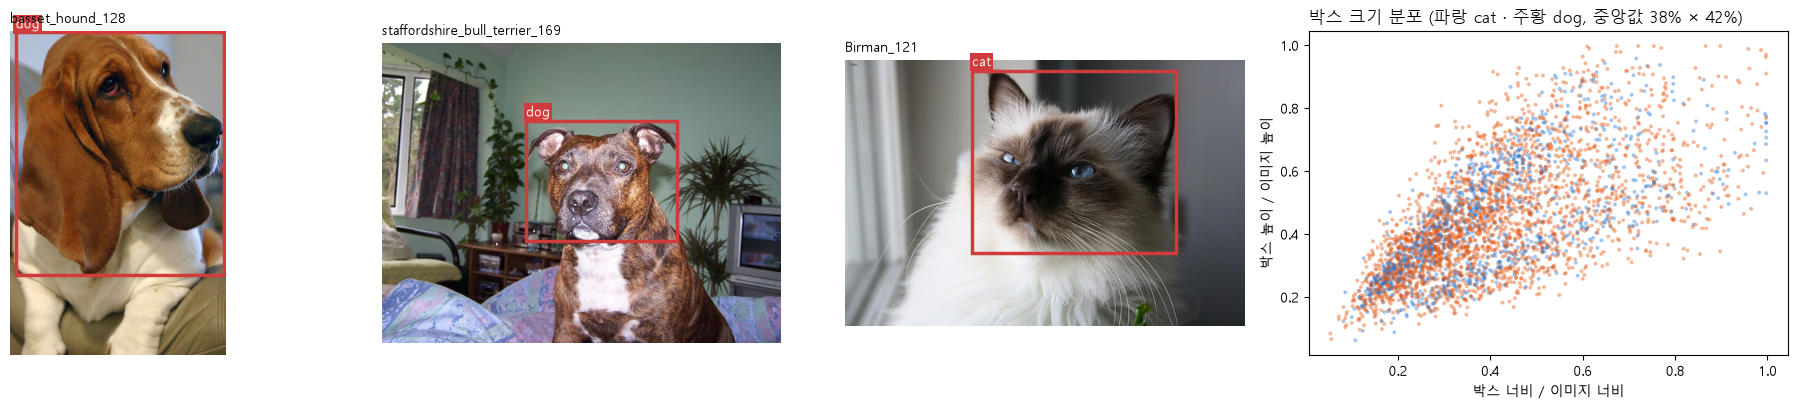

In [3]:
# XML 파싱 함수
def parse_xml(name):
    """XML에서 (이미지 너비, 높이, [(클래스, [x1, y1, x2, y2]), ...])를 읽는다."""
    tree = ET.parse(ann_dir / "xmls" / f"{name}.xml").getroot()  # 태그를 차례로 찾기 위해 최상위 태그부터
    width = int(tree.find("size").findtext("width"))  # 상대 크기 계산과 박스 범위 확인을 위해
    height = int(tree.find("size").findtext("height"))  # 상대 크기 계산과 박스 범위 확인을 위해
    objects = []  # 한 이미지에 여러 객체가 있어도 담기 위해
    for obj in tree.findall("object"):
        box = obj.find("bndbox")  # 좌표 태그만 꺼내기 위해
        coords = [int(box.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]  # 탐지 모델 입력 형식(XYXY)에 맞추기 위해
        objects.append((obj.findtext("name"), coords))  # 클래스와 좌표를 짝지어 두기 위해
    return width, height, objects

# 정답 있는 이미지 파싱
data = trainval[trainval["image"].isin(xml_names)].reset_index(drop=True)  # 정답 없는 9장을 빼기 위해
parsed = {name: parse_xml(name) for name in data["image"]}  # 학습 중 XML을 반복해서 읽지 않도록 미리 파싱

# 박스 통계
box_rows = []  # 박스별 상대 크기를 모으기 위해
for name, (w, h, objects) in parsed.items():
    for cls, (x1, y1, x2, y2) in objects:
        box_rows.append({"image": name, "class": cls, "rel_w": (x2 - x1) / w, "rel_h": (y2 - y1) / h})  # 이미지 크기와 무관하게 비교하기 위해 비율로
boxes = pd.DataFrame(box_rows)  # 집계 · 시각화를 위해 표로 변환
print(f"이미지 {len(data):,}장 · 박스 {len(boxes):,}개 · 이미지당 박스 수: {boxes.groupby('image').size().value_counts().to_dict()}")  # 이미지당 객체 수를 확인하기 위해
print("클래스별 박스:", boxes["class"].value_counts().to_dict())  # 클래스 불균형을 확인하기 위해

# 예시 3장 + 박스 크기 분포
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})  # 예시 3장과 산점도를 한 줄에 놓기 위해
for ax, name in zip(axes[:3], data.sample(3, random_state=SEED)["image"]):
    ax.imshow(Image.open(img_dir / f"{name}.jpg").convert("RGB"))  # 흑백 · RGBA 이미지도 같은 형식으로 보기 위해
    for cls, (x1, y1, x2, y2) in parsed[name][2]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="#d03b3b", linewidth=2.5))  # 박스가 가리키는 대상을 보기 위해
        ax.text(x1, y1 - 6, cls, color="white", fontsize=10, bbox=dict(facecolor="#d03b3b", edgecolor="none", pad=1.5))  # 박스 클래스를 표시하기 위해
    ax.set_title(name, loc="left", fontsize=10)  # 어느 이미지인지 알기 위해
    ax.axis("off")  # 사진만 보이도록 축 제거
colors = boxes["class"].map({"cat": "#2a78d6", "dog": "#e6550d"})  # 클래스별 분포를 구분하기 위해
axes[3].scatter(boxes["rel_w"], boxes["rel_h"], s=4, alpha=0.3, c=colors)  # 박스 크기 분포를 한눈에 보기 위해
axes[3].set_xlabel("박스 너비 / 이미지 너비")  # 축 의미를 알리기 위해
axes[3].set_ylabel("박스 높이 / 이미지 높이")  # 축 의미를 알리기 위해
axes[3].set_title(f"박스 크기 분포 (파랑 cat · 주황 dog, 중앙값 {boxes['rel_w'].median():.0%} × {boxes['rel_h'].median():.0%})", loc="left")  # 대표 크기를 함께 보이기 위해
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
이미지 3,671장 · 박스 3,672개 : 이미지당 거의 1개 (2개인 이미지 1장)
dog 2,490 · cat 1,182         : 강아지가 약 2.1배 → 2-1에서 품종 비율 유지 분할
박스 위치                     : 동물 전체가 아니라 얼굴(머리) 영역
상대 크기 중앙값 38% × 42%    : 중간 크기 물체 → 얼굴 경계를 얼마나 정확히 맞추는가가 성능을 가름
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| parse_xml() | 사용자 정의 함수 | XML → 크기 · 클래스 · 좌표 | `parse_xml(name)` |
| parse() · getroot()<br>find() · findtext() · findall() | xml.etree.ElementTree | XML 읽기 · 최상위 태그<br>태그 · 값 · 같은 태그 전부 | `ET.parse(...).getroot()`<br>`tree.findall("object")` |
| DataFrame() · reset_index() · sample()<br>map() · median() | pandas | 표 · 번호 재지정 · 무작위 예시<br>클래스 → 색 · 중앙값 | `data.sample(3, random_state=SEED)`<br>`boxes["class"].map({...})` |
| open() · convert() | PIL.Image | 이미지 읽기 · 3채널 통일 | `Image.open(...).convert("RGB")` |
| subplots() · imshow() · scatter()<br>Rectangle · add_patch() | matplotlib | 그래프 틀 · 이미지 · 산점도<br>박스 그리기 | `plt.subplots(1, 4, ...)`<br>`ax.add_patch(patches.Rectangle(...))` |
| int() · zip() | Python 내장 함수 | 정수 변환 · 칸과 이미지 짝 | `int(box.findtext(k))` · `zip(axes[:3], ...)` |
| def · return<br>컴프리헨션<br>튜플 풀기 | Python 기본 문법 | 함수 정의 · 여러 값 반환<br>좌표 목록 · 파싱 딕셔너리<br>좌표 4개 한 번에 | `def parse_xml(name):`<br>`{name: parse_xml(name) for ...}`<br>`for cls, (x1, y1, x2, y2) in objects:` |

---
## 2. 데이터 분할과 증강

### 2-1. 학습 · 검증 · 평가 분할

**한글 요약**

정답 있는 3,671장을 **37개 품종 비율을 유지**하며 학습 70% · 검증 15% · 평가 15%로 분할. 검증은 epoch마다 최고 가중치 선택, 평가 15%(**비교용 개발 평가셋**)는 학습에 쓰지 않고 4장에서 두 모델 비교에 사용.

**실행 흐름**

1. **입력**: 정답 있는 3,671장 `data` (품종 번호 `class_id`)
2. **처리**: 70 : 30 분할 → 30%를 다시 15 : 15 → 평가와 겹침 없음 확인
3. **저장**: `train_df` · `val_df` · `test_df`
4. **출력**: 분할별 이미지 수 · cat 비율 표

In [4]:
# 품종 비율 유지 분할
train_df, rest_df = train_test_split(data, test_size=0.3, stratify=data["class_id"], random_state=SEED)  # 세 데이터의 품종 구성을 같게 하기 위해 비율 유지
val_df, test_df = train_test_split(rest_df, test_size=0.5, stratify=rest_df["class_id"], random_state=SEED)  # 나머지를 검증 · 평가로 같은 비율로 나누기 위해
assert not set(train_df["image"]) & set(test_df["image"]) and not set(val_df["image"]) & set(test_df["image"])  # 평가 데이터 누수가 없도록 확인

# 분할 결과 표
display(pd.DataFrame({
    "이미지 수": [len(train_df), len(val_df), len(test_df)],  # 70 : 15 : 15로 나뉘었는지 보기 위해
    "cat 비율": [f"{(df['species'] == 1).mean():.1%}" for df in (train_df, val_df, test_df)],  # 종 비율이 고르게 나뉘었는지 보기 위해
}, index=["학습", "검증", "평가"]))  # 행 이름으로 분할을 구분하기 위해

,이미지 수,cat 비율
학습,2569,32.2%
검증,551,32.3%
평가,551,31.9%


**결과 해설**

```
학습 2,569 · 검증 551 · 평가 551 : 70 : 15 : 15 분할
cat 비율 32.2 · 32.3 · 31.9%     : 품종 비율 유지 분할로 세 데이터의 종 구성이 같음
assert 통과                      : 평가 데이터가 학습 · 검증과 겹치지 않음
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_test_split() | scikit-learn | 품종 비율 유지 분할 | `train_test_split(data, test_size=0.3, stratify=...)` |
| DataFrame() · mean() | pandas | 분할 결과 표 · True 비율 | `(df['species'] == 1).mean()` |
| set() · len() | Python 내장 함수 | 이름 집합 · 장수 | `set(train_df["image"])` · `len(train_df)` |
| assert · & 연산 | Python 기본 문법 | 교집합이 비었는지 검증 | `assert not set(...) & set(...)` |

### 2-2. Dataset · DataLoader · 증강

**한글 요약**

- 학습 데이터에만 **좌우 반전 · 색감 변화** 적용 (회전 · 자르기는 박스가 어긋나기 쉬워 제외)
- `tv_tensors.BoundingBoxes`로 좌우 반전 때 **박스 좌표도 함께 반전**
- 이미지 크기와 박스 수가 제각각이라 배치를 리스트로 묶음

<img src="images/m7_flip.png" alt="좌우 반전 때 박스 좌표 변환" width="862">

**실행 흐름**

1. **입력**: `train_df` · `val_df` · `test_df`, 1-2의 `parsed`
2. **처리**: 변환 정의 → Dataset(이미지 · 박스 · 라벨 동시 변환) → 배치 묶음 함수
3. **저장**: `train_tf` · `eval_tf` · `loaders`
4. **출력**: 첫 학습 배치의 장수 · 이미지 크기 · 정답

In [5]:
# 변환 정의
train_tf = v2.Compose([
    v2.ToImage(),  # 모델이 받는 텐서 형식으로 바꾸기 위해
    v2.RandomHorizontalFlip(p=0.5),  # 얼굴 방향 차이에 강해지도록 (박스 좌표도 함께 반전)
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),  # 조명 · 색감 차이에 강해지도록
    v2.ToDtype(torch.float32, scale=True),  # 0~255를 0~1로 맞추기 위해
])
eval_tf = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])  # 매번 같은 입력으로 공정하게 비교하기 위해 증강 없이

# 데이터셋 정의
class PetDataset(Dataset):
    """이미지와 박스 정답을 (이미지 텐서, {"boxes", "labels"}) 형태로 돌려준다."""

    def __init__(self, df, transform):
        self.names = df["image"].tolist()  # 순서대로 꺼내기 위해 이름 목록 저장
        self.transform = transform  # 학습 · 평가에 다른 변환을 쓰기 위해

    def __len__(self):
        return len(self.names)  # DataLoader가 데이터 수를 알도록

    def __getitem__(self, i):
        name = self.names[i]  # i번째 이미지를 찾기 위해
        image = Image.open(img_dir / f"{name}.jpg").convert("RGB")  # 흑백 · RGBA 이미지도 3채널로 통일하기 위해
        w, h, objects = parsed[name]  # 1-2에서 미리 읽은 정답을 재사용하기 위해
        boxes = tv_tensors.BoundingBoxes([coords for _, coords in objects], format="XYXY", canvas_size=(h, w))  # 반전 때 이미지 너비 기준으로 좌표가 바뀌도록
        labels = torch.tensor([CLASSES.index(cls) for cls, _ in objects])  # 모델이 받는 클래스 번호로 바꾸기 위해
        image, target = self.transform(image, {"boxes": boxes, "labels": labels})  # 이미지와 박스를 같은 변환으로 맞추기 위해
        return image, target

# 배치 묶음 함수
def collate(batch):
    """이미지 크기와 박스 수가 제각각이라 하나의 텐서로 쌓지 않고 리스트로 묶는다."""
    return tuple(zip(*batch))  # 크기가 다른 이미지를 쌓지 않고 묶기 위해

# 데이터 로더
loaders = {
    "train": DataLoader(PetDataset(train_df, train_tf), batch_size=16, shuffle=True, collate_fn=collate,
                        generator=torch.Generator().manual_seed(SEED)),  # 매 epoch 섞되 순서를 재현하기 위해
    "val": DataLoader(PetDataset(val_df, eval_tf), batch_size=32, collate_fn=collate),  # epoch별 최고 가중치를 고르기 위해
    "test": DataLoader(PetDataset(test_df, eval_tf), batch_size=32, collate_fn=collate),  # 마지막에 한 번만 평가하기 위해
}
images, targets = next(iter(loaders["train"]))  # 형식을 점검하기 위해 첫 배치만 꺼냄
print(f"학습 배치: 이미지 {len(images)}장 · 첫 이미지 {tuple(images[0].shape)} · 첫 정답 {targets[0]['labels'].tolist()} {targets[0]['boxes'].tolist()}")  # 모델 입력 형식이 맞는지 확인하기 위해

학습 배치: 이미지 16장 · 첫 이미지 (3, 333, 500) · 첫 정답 [1] [[167, 81, 347, 221]]


**결과 해설**

```
이미지 16장               : 배치 크기 16
(3, 333, 500)             : 채널 3 · 원본 크기 유지 (모델 안에서 300 · 320으로 크기 조정)
[1] [[167, 81, 347, 221]] : 라벨 1(cat) · 박스 좌표 x1, y1, x2, y2
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| PetDataset · collate() | 사용자 정의 클래스 · 함수 | 이미지 · 박스 · 라벨 공급, 리스트 묶음 | `PetDataset(train_df, train_tf)` · `collate_fn=collate` |
| Compose · ToImage · ToDtype<br>RandomHorizontalFlip · ColorJitter | torchvision.transforms.v2 | 변환 묶기 · 텐서 · 0~1<br>좌우 반전 · 색감 변화 | `v2.Compose([...])`<br>`v2.RandomHorizontalFlip(p=0.5)` |
| BoundingBoxes | torchvision.tv_tensors | 이미지와 함께 변환되는 박스 | `tv_tensors.BoundingBoxes(..., format="XYXY")` |
| Dataset · DataLoader | torch.utils.data | 데이터셋 틀 · 배치 공급 | `DataLoader(..., batch_size=16, shuffle=True)` |
| tensor() · Generator() | torch | 라벨 텐서 · 섞는 순서 재현 | `torch.Generator().manual_seed(SEED)` |
| zip() · tuple() · next() · iter() | Python 내장 함수 | 배치 나누기 · 첫 배치 | `tuple(zip(*batch))` · `next(iter(...))` |
| class · __getitem__<br>* 풀기 | Python 기본 문법 | Dataset 규칙 클래스<br>배치를 zip 인자로 | `def __getitem__(self, i):`<br>`zip(*batch)` |

---
## 3. 모델 학습

### 3-1. 분류 헤드 교체

**한글 요약**

- COCO(91클래스) 사전학습 SSD300 · SSDLite의 분류 헤드를 **3클래스용으로 새로 생성**해 교체
- 기본 예시 코드처럼 `num_classes` **속성값만 바꾸면 예측층이 그대로**라는 점을 출력 채널로 확인
- SSD300-VGG16은 300 × 300 · 정확도 위주, SSDLite320-MobileNetV3는 320 × 320 · 모바일용 경량 구조

<img src="images/m7_head.png" alt="속성 변경과 헤드 새로 생성의 출력 채널 비교" width="837">

**실행 흐름**

1. **입력**: COCO 사전학습 가중치
2. **처리**: 속성만 바꾼 모델의 출력 채널 확인 → 헤드를 새로 만드는 두 함수 정의
3. **저장**: `build_ssd300` · `build_ssdlite`
4. **출력**: 교체 전후 출력 채널 · 두 모델 파라미터 수

In [6]:
# 속성값만 바꾼 경우
wrong = ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)  # 기본 예시 방식을 재현하기 위해 COCO 모델 생성
anchors = wrong.anchor_generator.num_anchors_per_location()  # 출력 채널 = 앵커 수 × 클래스 수를 계산하기 위해
before = wrong.head.classification_head.module_list[0].out_channels  # 변경 전 예측층 크기를 기록하기 위해
wrong.head.classification_head.num_classes = 3  # 기본 예시 코드 방식이 효과가 있는지 보기 위해
after = wrong.head.classification_head.module_list[0].out_channels  # 예측층이 실제로 바뀌었는지 확인하기 위해
print(f"[속성만 변경] 첫 예측층 출력 채널: {before} → {after} (앵커 {anchors[0]} × 91클래스 그대로)")  # 변화가 없음을 보이기 위해

# SSD300 헤드 교체
def build_ssd300():
    model = ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)  # 적은 데이터로도 학습되도록 사전학습 가중치 사용
    in_channels = det_utils.retrieve_out_channels(model.backbone, (300, 300))  # 새 헤드 입력 크기를 백본에 맞추기 위해
    num_anchors = model.anchor_generator.num_anchors_per_location()  # 새 헤드가 기존 앵커 구성을 따르도록
    model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, len(CLASSES))  # 3클래스를 예측하도록 헤드 교체
    return model

# SSDLite 헤드 교체
def build_ssdlite():
    model = ssdlite320_mobilenet_v3_large(weights=SSDLite320_MobileNet_V3_Large_Weights.DEFAULT)  # 적은 데이터로도 학습되도록 사전학습 가중치 사용
    in_channels = [block[0][0].in_channels for block in model.head.classification_head.module_list]  # 새 헤드 입력 크기를 기존 헤드와 같게 하기 위해
    num_anchors = model.anchor_generator.num_anchors_per_location()  # 새 헤드가 기존 앵커 구성을 따르도록
    norm_layer = partial(nn.BatchNorm2d, eps=0.001, momentum=0.03)  # SSDLite 기본 정규화 설정을 그대로 쓰기 위해
    model.head.classification_head = SSDLiteClassificationHead(in_channels, num_anchors, len(CLASSES), norm_layer)  # 3클래스를 예측하도록 헤드 교체
    return model

# 교체 결과 확인
fixed = build_ssd300()  # 교체가 제대로 됐는지 확인하기 위해
fixed_channels = fixed.head.classification_head.module_list[0].out_channels  # 새 예측층 크기를 보기 위해
print(f"[헤드 새로 생성] 첫 예측층 출력 채널: {fixed_channels} (앵커 {anchors[0]} × 3클래스)")  # 3클래스 출력이 됐음을 보이기 위해
for name, model in [("SSD300-VGG16", fixed), ("SSDLite320-MobileNetV3", build_ssdlite())]:
    print(f"{name:<24} 파라미터 {sum(p.numel() for p in model.parameters()):>11,}")  # 두 모델 크기를 비교하기 위해
del wrong, fixed  # 확인용 모델이 메모리를 차지하지 않도록
assert after == before and fixed_channels == anchors[0] * len(CLASSES)  # 속성 변경은 효과 없고 교체는 3클래스임을 검증하기 위해

[속성만 변경] 첫 예측층 출력 채널: 364 → 364 (앵커 4 × 91클래스 그대로)


[헤드 새로 생성] 첫 예측층 출력 채널: 12 (앵커 4 × 3클래스)
SSD300-VGG16             파라미터  23,879,570
SSDLite320-MobileNetV3   파라미터   2,220,380


**결과 해설**

```
속성만 변경: 364 → 364 : 앵커 4 × 91클래스 그대로 → 헤드가 바뀌지 않음
헤드 새로 생성: 12     : 앵커 4 × 3클래스 → 배경 · cat · dog 예측
SSD300 23,879,570      : 약 2,388만 개
SSDLite 2,220,380      : 약 222만 개, SSD300의 약 1/11
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| build_ssd300() · build_ssdlite() | 사용자 정의 함수 | 3클래스 헤드로 교체한 모델 | `build_ssd300()` · `build_ssdlite()` |
| ssd300_vgg16() · ssdlite320_...()<br>SSD(Lite)ClassificationHead<br>retrieve_out_channels()<br>num_anchors_per_location() | torchvision.models.detection | 사전학습 탐지 모델<br>분류 헤드 생성<br>특징맵별 채널 수<br>위치당 앵커 수 | `ssd300_vgg16(weights=...)`<br>`SSDClassificationHead(...)`<br>`det_utils.retrieve_out_channels(...)`<br>`model.anchor_generator...` |
| BatchNorm2d · numel() | torch.nn | 정규화 층 · 파라미터 수 | `sum(p.numel() for p in ...)` |
| partial() | functools | 인자를 미리 채운 층 | `partial(nn.BatchNorm2d, eps=0.001, momentum=0.03)` |
| del · assert<br>f-문자열 {:<24} · {:>11,} | Python 기본 문법 | 메모리 해제 · 검증<br>정렬 · 천 단위 쉼표 | `del wrong, fixed`<br>`f"{name:<24} ..."` |

### 3-2. 예측 · 평가 함수

**한글 요약**

- **predict**: 데이터 전체의 예측 박스 · 점수 · 클래스와 정답 수집
- **coco_map**: COCO 방식 mAP@[.5:.95] · mAP@50 · mAP@75 · 클래스별 AP 계산
- 정답을 그대로 예측으로 넣었을 때 mAP 1.0이 나오는지 검산

<img src="images/m7_iou.png" alt="IoU 정의와 mAP@50 · mAP@75 · mAP@[.5:.95] 기준" width="837">

**실행 흐름**

1. **입력**: 모델 · DataLoader (검산은 박스 1개짜리 예시)
2. **처리**: 이미지별 예측 · 정답 수집 → torchmetrics로 mAP 계산 → 정답 = 예측 검산
3. **저장**: `predict` · `coco_map` 함수
4. **출력**: 없음 (assert 통과 여부)

In [7]:
# 예측 수집 함수
@torch.no_grad()
def predict(model, loader):
    """데이터 전체의 예측 박스 · 점수 · 클래스와 정답을 모은다."""
    model.eval()  # 증강 · 학습용 동작을 끄기 위해 평가 모드
    preds, gts = [], []  # 평가 함수에 한 번에 넘기기 위해 목록으로
    for images, targets in loader:
        outputs = model([img.to(device) for img in images])  # GPU에서 이미지별 예측을 얻기 위해
        for out, tgt in zip(outputs, targets):
            preds.append({"boxes": out["boxes"].cpu(), "scores": out["scores"].cpu(), "labels": out["labels"].cpu()})  # GPU 메모리를 비우기 위해 CPU로 이동
            gts.append({"boxes": tgt["boxes"].as_subclass(torch.Tensor), "labels": tgt["labels"]})  # torchmetrics 입력 형식에 맞추기 위해 일반 텐서로
    return preds, gts

# COCO mAP 함수
def coco_map(preds, gts):
    """COCO 방식 mAP@[.5:.95] · mAP@50 · mAP@75와 클래스별 AP"""
    metric = MeanAveragePrecision(iou_type="bbox", class_metrics=True)  # 박스 기준 · 클래스별 AP까지 보기 위해
    metric.warn_on_many_detections = False  # COCO 표준대로 이미지당 상위 100개만 평가한다는 안내가 평가마다 반복되지 않도록
    metric.update(preds, gts)  # 예측 · 정답을 한 번에 넣기 위해
    result = metric.compute()  # 놓친 정답까지 반영한 지표를 얻기 위해
    scores = {"mAP@[.5:.95]": result["map"].item(), "mAP@50": result["map_50"].item(), "mAP@75": result["map_75"].item()}  # 표로 비교하기 쉽도록 숫자로
    class_ids = result["classes"].reshape(-1).tolist()  # 클래스가 1개여도 목록 형태가 되도록
    class_aps = result["map_per_class"].reshape(-1).tolist()  # 클래스가 1개여도 목록 형태가 되도록
    for class_id, ap in zip(class_ids, class_aps):
        scores[f"AP {CLASSES[class_id]}"] = ap  # 읽기 쉽도록 클래스 이름으로 저장
    return scores

# 지표 검산
sample_gts = [{"boxes": torch.tensor([[10.0, 10, 50, 50]]), "labels": torch.tensor([1])}]  # 답이 분명한 예시를 만들기 위해 정답 1개
sample_preds = [{"boxes": torch.tensor([[10.0, 10, 50, 50]]), "scores": torch.tensor([0.9]), "labels": torch.tensor([1])}]  # 정답과 같은 예측으로 검산하기 위해
assert coco_map(sample_preds, sample_gts)["mAP@[.5:.95]"] == 1.0  # 평가 함수가 올바른지 확인하기 위해

**결과 해설**

```
출력 없음   : 함수 정의 셀
assert 통과 : 정답 = 예측일 때 mAP 1.0 → 평가 함수가 올바르게 동작
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| predict() · coco_map() | 사용자 정의 함수 | 예측 수집 · mAP 계산 | `coco_map(*predict(model, loader))` |
| MeanAveragePrecision<br>update() · compute() | torchmetrics.detection | COCO 방식 mAP 계산기<br>입력 · 계산 | `MeanAveragePrecision(iou_type="bbox", class_metrics=True)`<br>`metric.update(preds, gts)` |
| no_grad() · tensor() | torch | 기울기 계산 끄기 · 검산 텐서 | `@torch.no_grad()` · `torch.tensor([[10.0, 10, 50, 50]])` |
| to() · cpu() · as_subclass()<br>reshape() · tolist() · item() | torch.Tensor | 장치 이동 · 일반 텐서<br>1차원 · 목록 · 숫자 | `out["boxes"].cpu()`<br>`result["classes"].reshape(-1).tolist()` |
| eval() | torch.nn.Module | 평가 모드 | `model.eval()` |
| zip() | Python 내장 함수 | 예측 · 정답 짝 | `zip(outputs, targets)` |
| @ 데코레이터 · * 풀기 | Python 기본 문법 | 함수 전체 no_grad · 인자 펼치기 | `@torch.no_grad()` · `coco_map(*...)` |

### 3-3. 학습 함수

**한글 요약**

매 epoch 검증 mAP를 계산해 **최고 시점 가중치**를 남기는 학습 함수. 학습률은 OneCycle(처음 10% 워밍업 후 감소)을 배치마다 조정.

**실행 흐름**

1. **입력**: 모델 생성 함수 · epoch 수 · 옵티마이저 생성 함수
2. **처리**: 배치 학습 → epoch마다 검증 mAP → 최고 기록이면 가중치 복사 → 끝나면 복원
3. **저장**: `train` 함수 (반환: 모델 · epoch 기록 · 학습 시간)
4. **출력**: 없음 (3-4에서 실행)

In [8]:
# 학습 함수
def train(build, epochs, make_optimizer):
    """학습하면서 검증 mAP가 가장 높은 epoch의 가중치를 남긴다."""
    torch.manual_seed(SEED)  # 두 모델 · 재실행이 같은 초기 헤드 가중치에서 출발하도록
    model = build().to(device)  # GPU에서 학습하기 위해
    optimizer = make_optimizer(model.parameters())  # 모델마다 다른 옵티마이저를 쓰기 위해 함수로 받음
    max_lrs = [group["lr"] for group in optimizer.param_groups]  # 옵티마이저 학습률을 OneCycle 최고점으로 쓰기 위해
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs,
                                                    total_steps=epochs * len(loaders["train"]), pct_start=0.1)  # 초반 발산을 막기 위해 10% 워밍업 후 감소
    best_map, best_state, history = -1.0, None, []  # 최고 기록 · 가중치 · 학습 곡선을 남기기 위해
    start = time.time()  # 학습 시간을 재기 위해
    for epoch in range(epochs):
        model.train()  # 학습용 동작을 켜기 위해 학습 모드
        total_loss = 0.0  # epoch 평균 손실을 구하기 위해
        for images, targets in loaders["train"]:
            images = [img.to(device) for img in images]  # GPU에서 계산하기 위해
            targets = [{"boxes": t["boxes"].as_subclass(torch.Tensor).to(device), "labels": t["labels"].to(device)} for t in targets]  # 정답도 같은 장치에 두기 위해
            loss_dict = model(images, targets)  # 박스 회귀 · 분류 손실을 얻기 위해
            loss = sum(loss_dict.values())  # 두 손실을 함께 줄이기 위해 합산
            optimizer.zero_grad()  # 이전 배치 기울기가 섞이지 않도록
            loss.backward()  # 가중치별 기울기를 구하기 위해
            optimizer.step()  # 손실이 줄어드는 방향으로 가중치를 고치기 위해
            scheduler.step()  # total_steps를 배치 수로 잡았기 때문에 배치마다 조정
            total_loss += loss.item()  # epoch 평균을 내기 위해 누적
        scores = coco_map(*predict(model, loaders["val"]))  # 최고 epoch를 고르기 위해 검증 mAP 계산
        history.append({"epoch": epoch + 1, "loss": total_loss / len(loaders["train"]), **scores})  # 학습 곡선을 그리기 위해 기록
        if scores["mAP@[.5:.95]"] > best_map:  # 검증 최고 기록일 때만 저장하기 위해
            best_map = scores["mAP@[.5:.95]"]  # 다음 epoch와 비교하기 위해
            best_state = copy.deepcopy(model.state_dict())  # 이후 학습이 덮어써도 보존되도록 복사
    model.load_state_dict(best_state)  # 과적합된 마지막 epoch 대신 최고 시점을 쓰기 위해
    return model, pd.DataFrame(history), time.time() - start

**결과 해설**

```
출력 없음      : 함수 정의 셀, 3-4에서 두 모델에 사용
최고 시점 복원 : 마지막 epoch가 아니라 검증 mAP가 가장 높았던 가중치로 평가
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train() | 사용자 정의 함수 | 최고 epoch를 남기는 학습 | `train(build, epochs, make_optimizer)` |
| manual_seed()<br>lr_scheduler.OneCycleLR | torch | 초기 가중치 재현<br>워밍업 후 감소하는 학습률 | `torch.manual_seed(SEED)`<br>`OneCycleLR(optimizer, max_lr=..., pct_start=0.1)` |
| train() · state_dict() · load_state_dict() | torch.nn.Module | 학습 모드 · 가중치 꺼내기 · 되돌리기 | `model.load_state_dict(best_state)` |
| zero_grad() · step() | torch.optim | 기울기 초기화 · 갱신 | `optimizer.zero_grad()` · `optimizer.step()` |
| backward() · item() | torch.Tensor | 역전파 · 숫자 꺼내기 | `loss.backward()` · `loss.item()` |
| deepcopy()<br>time() | copy · time | 가중치 보관<br>학습 시간 | `copy.deepcopy(model.state_dict())`<br>`time.time() - start` |
| sum() · range() | Python 내장 함수 | 손실 합 · epoch 반복 | `sum(loss_dict.values())` · `range(epochs)` |
| ** 풀기 · += 누적 | Python 기본 문법 | 지표 딕셔너리 합치기 · 손실 누적 | `{"epoch": ..., **scores}` · `total_loss += ...` |

### 3-4. 두 모델 학습

**한글 요약**

SSD300은 원 논문 방식인 **SGD로 15 epoch**, 가벼운 SSDLite는 **AdamW로 40 epoch** 학습. 학습 손실과 검증 mAP 곡선으로 학습 과정 비교.

**실행 흐름**

1. **입력**: 3-1의 모델 생성 함수 · 3-3의 `train`
2. **처리**: 모델별 옵티마이저 정의 → 모델별 학습(최고 epoch 복원) → 검증 mAP 차이 0.01 미만이면 작은 모델을 최종 모델로 → epoch 기록으로 곡선
3. **저장**: `trained` · `histories` · `train_minutes` · `best_name`
4. **출력**: 최고 검증 mAP · 학습 시간, 학습 손실 · 검증 mAP 그래프

SSD300-VGG16             최고 검증 mAP 0.7758 (15/15 epoch) · 학습 20.2분


SSDLite320-MobileNetV3   최고 검증 mAP 0.7720 (31/40 epoch) · 학습 27.8분


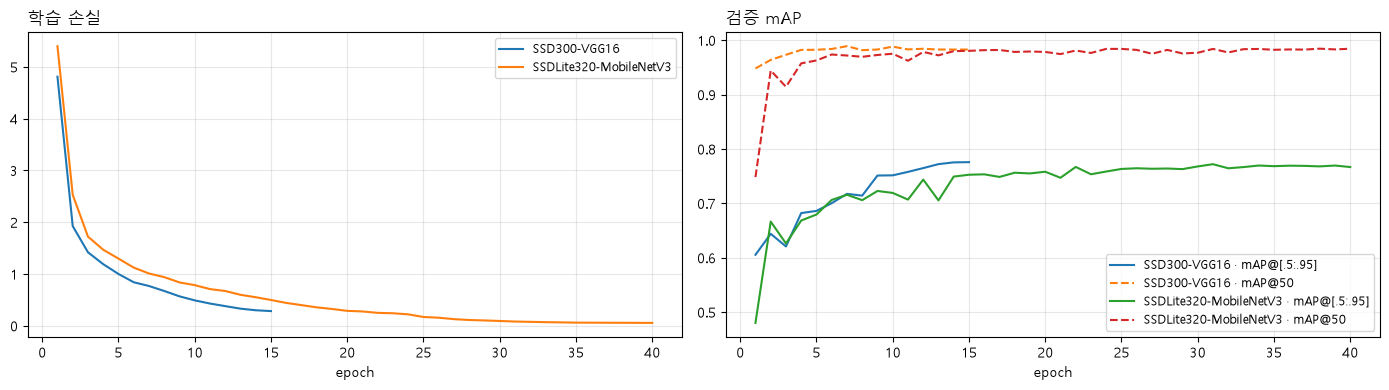

In [9]:
# 모델별 옵티마이저
def ssd300_optimizer(params):
    return torch.optim.SGD(params, lr=2e-3, momentum=0.9, weight_decay=5e-4)  # 원 논문 설정을 따르기 위해
def ssdlite_optimizer(params):
    return torch.optim.AdamW(params, lr=1e-3, weight_decay=1e-4)  # 작은 모델을 빠르게 수렴시키기 위해

# 두 모델 학습
runs = {
    "SSD300-VGG16": (build_ssd300, 15, ssd300_optimizer),  # 같은 반복문으로 학습하기 위해 (모델 생성, epoch, 옵티마이저)
    "SSDLite320-MobileNetV3": (build_ssdlite, 40, ssdlite_optimizer),  # 한 epoch가 가벼워 더 길게 학습하기 위해
}
trained, histories, train_minutes = {}, {}, {}  # 4장 평가에서 다시 쓰기 위해 보관
for name, (build, epochs, make_optimizer) in runs.items():
    model, history, seconds = train(build, epochs, make_optimizer)  # 최고 epoch 가중치로 복원된 모델을 얻기 위해
    trained[name], histories[name], train_minutes[name] = model, history, seconds / 60  # 4장 평가 · 곡선에 쓰기 위해
    best = history.loc[history["mAP@[.5:.95]"].idxmax()]  # 최고 epoch를 확인하기 위해
    print(f"{name:<24} 최고 검증 mAP {best['mAP@[.5:.95]']:.4f} ({int(best['epoch'])}/{epochs} epoch) · 학습 {seconds / 60:.1f}분")  # 진행 상황을 확인하기 위해

# 최종 모델 선택 (검증 mAP · 모델 크기 기준)
val_best = {name: h["mAP@[.5:.95]"].max() for name, h in histories.items()}  # 모델별 최고 검증 mAP를 비교하기 위해
close = [n for n, v in val_best.items() if max(val_best.values()) - v < 0.01]  # 차이 0.01 미만은 같은 수준으로 보기 위해
best_name = min(close, key=lambda n: sum(p.numel() for p in trained[n].parameters()))  # 같은 수준이면 배포에 유리한 작은 모델을 고르기 위해

# 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(14, 4))  # 손실과 mAP를 나란히 비교하기 위해
for name, history in histories.items():
    axes[0].plot(history["epoch"], history["loss"], label=name)  # 학습이 수렴하는지 보기 위해
    axes[1].plot(history["epoch"], history["mAP@[.5:.95]"], label=f"{name} · mAP@[.5:.95]")  # 박스 정밀도까지 반영한 성능을 보기 위해
    axes[1].plot(history["epoch"], history["mAP@50"], linestyle="--", label=f"{name} · mAP@50")  # 대략적인 위치 찾기 성능과 구분하기 위해
axes[0].set_title("학습 손실", loc="left")  # 그래프 내용을 알리기 위해
axes[1].set_title("검증 mAP", loc="left")  # 그래프 내용을 알리기 위해
for ax in axes:
    ax.set_xlabel("epoch")  # 가로축 의미를 알리기 위해
    ax.grid(alpha=0.3)  # 값을 읽기 쉽도록 옅은 격자
    ax.legend(fontsize=8.5)  # 선을 구분하기 위해
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
SSD300 검증 0.7758 (15/15)  : 마지막 epoch에 최고 → 아직 오르는 중, 더 학습할 여지
SSDLite 검증 0.7720 (31/40) : 25 epoch 이후 거의 평평
mAP@50                      : 두 모델 모두 처음 몇 epoch 만에 0.95 이상 → 얼굴 위치는 금방 찾음
mAP@[.5:.95]                : 학습 내내 천천히 상승 → 학습으로 좋아지는 것은 주로 박스 경계 정밀도
학습 20.2분 · 27.8분        : SSD300 15 epoch · SSDLite 40 epoch (실행 환경마다 다름)
```

- **최종 모델 SSDLite320-MobileNetV3**: 검증 mAP 차이 0.0038(0.7758 - 0.7720) < 0.01 → 같은 수준이므로 파라미터가 1/11인 쪽 선택
- 현재 노트북 실행 순서에서는 평가 계산 전에 선택. 다만 0.01 규칙은 기존 평가 결과를 본 뒤 정한 **사후 규칙**이라 독립적인 사전 등록 선택은 아님 (재현성 절 참고)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| ssd300_optimizer() · ssdlite_optimizer() | 사용자 정의 함수 | 모델별 옵티마이저 | `ssd300_optimizer(params)` |
| SGD · AdamW | torch.optim | 모멘텀 경사 하강 · 가중치 감쇠 Adam | `torch.optim.SGD(params, lr=2e-3, momentum=0.9, ...)` |
| idxmax() · loc[] | pandas | 최고 epoch 위치 · 행 꺼내기 | `history.loc[history["mAP@[.5:.95]"].idxmax()]` |
| subplots() · plot()<br>set_title() · grid() · legend() | matplotlib | 그래프 틀 · 선<br>제목 · 격자 · 범례 | `plt.subplots(1, 2, figsize=(14, 4))`<br>`ax.grid(alpha=0.3)` |
| items() · int()<br>max() · min() | Python 내장 함수 | 딕셔너리 순회 · 정수<br>최고 검증 mAP · 가장 작은 모델 | `runs.items()` · `int(best['epoch'])`<br>`min(close, key=...)` |
| 함수를 값으로 전달<br>여러 변수 동시 대입<br>컴프리헨션 · lambda | Python 기본 문법 | 모델별 설정 묶기<br>세 결과 한 줄 저장<br>후보 목록 · 크기 기준 | `(build_ssd300, 15, ssd300_optimizer)`<br>`trained[name], histories[name], ... = ...`<br>`key=lambda n: sum(...)` |

---
## 4. 평가 (비교용 개발 평가셋 551장)

### 4-1. 정확도와 효율

**한글 요약**

학습에 쓰지 않은 **비교용 개발 평가셋** 551장에서 3-4에서 고른 최종 모델(SSDLite)과 SSD300의 **mAP · 클래스별 AP**와 **파라미터 수 · 추론 속도 · 학습 시간** 비교. 선택 규칙을 이 데이터의 이전 결과를 본 뒤 정했으므로 여기 수치는 독립 최종 성능이 아닌 **사후 확인 성능**.

**실행 흐름**

1. **입력**: 학습된 두 모델 · 평가 DataLoader
2. **처리**: 개발 평가셋 예측 → COCO mAP → 파라미터 수 · 8장 배치 추론 속도 측정
3. **저장**: `test_preds` · `result`
4. **출력**: 모델 × 지표 비교표 (최고값 강조)

In [10]:
# 추론 속도 측정 함수
@torch.no_grad()
def images_per_second(model, repeat=12):
    """8장 배치를 반복 추론해 초당 처리 이미지 수를 잰다."""
    model.eval()  # 실제 추론 조건으로 재기 위해 평가 모드
    batch = [loaders["test"].dataset[i][0].to(device) for i in range(8)]  # 두 모델을 같은 입력으로 재기 위해 고정 8장
    model(batch)  # 첫 실행의 준비 시간이 측정에 섞이지 않도록
    torch.cuda.synchronize()  # GPU는 비동기로 실행되므로 앞선 작업이 끝날 때까지 대기
    start = time.time()  # 측정 시작 시각을 기록하기 위해
    for _ in range(repeat):
        model(batch)  # 측정 오차를 줄이기 위해 같은 배치를 반복
    torch.cuda.synchronize()  # 마지막 작업까지 끝난 뒤 시간을 재기 위해
    return repeat * len(batch) / (time.time() - start)  # 모델 간 비교가 쉽도록 장/초로

# 모델별 평가
test_preds, rows = {}, {}  # 4-2 · 4-3에서 같은 예측을 재사용하기 위해 보관
for name, model in trained.items():
    test_preds[name] = predict(model, loaders["test"])  # 평가 데이터 예측을 한 번만 하기 위해 저장
    rows[name] = coco_map(*test_preds[name])  # 놓친 정답까지 반영한 정확도를 얻기 위해
    rows[name]["파라미터(백만)"] = sum(p.numel() for p in model.parameters()) / 1e6  # 모델 크기를 비교하기 위해
    rows[name]["추론 속도(장/초)"] = images_per_second(model)  # 실시간 사용 가능성을 비교하기 위해
    rows[name]["학습 시간(분)"] = train_minutes[name]  # 학습 비용도 함께 비교하기 위해 3-4 값 사용
result = pd.DataFrame(rows).T  # 모델을 행으로 보기 위해 행열 전환

# 비교표
table_format = {c: "{:.4f}" for c in result.columns if c.startswith(("mAP", "AP"))}  # 지표 차이를 읽을 수 있도록 소수 넷째 자리
table_format.update({"파라미터(백만)": "{:.1f}", "추론 속도(장/초)": "{:.0f}", "학습 시간(분)": "{:.1f}"})  # 효율 지표는 읽기 쉬운 자릿수로
result.style.format(table_format).highlight_max(subset=["mAP@[.5:.95]", "mAP@75", "추론 속도(장/초)"], color="#d4edda")  # 우세한 쪽을 한눈에 보기 위해 강조

,mAP@[.5:.95],mAP@50,mAP@75,AP cat,AP dog,파라미터(백만),추론 속도(장/초),학습 시간(분)
SSD300-VGG16,0.7794,0.9883,0.9141,0.8325,0.7262,23.9,101,20.2
SSDLite320-MobileNetV3,0.7856,0.9903,0.9254,0.8313,0.7398,2.2,244,27.8


**결과 해설**

```
mAP@[.5:.95] 0.7856 vs 0.7794  : SSDLite가 0.006 높음 → 정확도는 비슷
mAP@50 0.9903 vs 0.9883        : 절반 이상 겹침 기준으로는 둘 다 0.99 수준
mAP@75 0.9254 vs 0.9141        : 박스를 더 정밀하게 요구하면 SSDLite가 조금 높음
AP cat 0.83 · AP dog 0.73~0.74 : 강아지는 25개 품종의 얼굴 모양이 다양해 경계 맞추기 어려움
파라미터 2.2M vs 23.9M         : SSDLite가 1/11 크기
추론 244 vs 101장/초           : SSDLite가 2.4배 빠름
```

- 최종 모델 **SSDLite320-MobileNetV3**는 3-4에서 검증 기준으로 이미 확정, SSD300 수치는 비교용 참고값

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| images_per_second() | 사용자 정의 함수 | 추론 속도 측정 | `images_per_second(model)` |
| cuda.synchronize() | torch | GPU 작업 완료 대기 | `torch.cuda.synchronize()` |
| DataFrame() · T<br>style.format() · highlight_max() | pandas | 표 · 행열 전환<br>서식 · 최고값 강조 | `pd.DataFrame(rows).T`<br>`result.style.format(...).highlight_max(...)` |
| startswith() · update() | Python 내장 메서드 | 지표 열 고르기 · 서식 합치기 | `c.startswith(("mAP", "AP"))` |
| range() · len() · sum() | Python 내장 함수 | 반복 · 장수 · 파라미터 합 | `range(repeat)` · `len(batch)` |
| _ 변수 · 조건 컴프리헨션 | Python 기본 문법 | 쓰지 않는 변수 · 지표 열만 서식 | `for _ in range(repeat):` |

### 4-2. 평가 방식 검증

**한글 요약**

기본 예시 코드의 AP 계산은 **예측과 정답이 모두 있는 이미지만** 모아 계산 → 모델이 얼굴을 놓친 경우가 점수에서 빠짐. 같은 예측에 두 방식을 적용해 차이 확인.

<img src="images/m7_apcalc.png" alt="기본 예시 AP와 COCO 방식의 계산 범위 차이" width="837">

**실행 흐름**

1. **입력**: 4-1의 평가 예측 `test_preds`
2. **처리**: 두 박스 IoU 함수 → 기본 예시 방식 AP@50 (예측 · 정답 없는 이미지 건너뜀) → COCO mAP@50과 비교
3. **저장**: `compare` 표
4. **출력**: 모델 × 두 방식 AP@50 표

In [11]:
# 두 박스 IoU
def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])  # 겹친 영역의 왼쪽 위를 구하기 위해
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])  # 겹친 영역의 오른쪽 아래를 구하기 위해
    inter = max(0, x2 - x1) * max(0, y2 - y1)  # 안 겹치면 0이 되도록
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # 겹친 부분을 두 번 세지 않도록
    return inter / union

# 기본 예시 방식 AP@50
def example_style_ap50(preds, gts):
    """기본 예시 방식: 예측 · 정답이 모두 있는 이미지만 집계 (놓친 정답 미반영)"""
    ap_list = []  # 클래스별 AP를 평균 내기 위해
    for class_id in (1, 2):
        is_tp, scores = [], []  # 점수 순위로 AP를 계산하기 위해
        for pred, gt in zip(preds, gts):
            pred_boxes = pred["boxes"][pred["labels"] == class_id].tolist()  # 이 클래스만 평가하기 위해
            pred_scores = pred["scores"][pred["labels"] == class_id].tolist()  # 이 클래스만 평가하기 위해
            gt_boxes = gt["boxes"][gt["labels"] == class_id].tolist()  # 이 클래스만 평가하기 위해
            if not pred_boxes or not gt_boxes:
                continue  # 기본 예시 방식을 재현하기 위해 건너뜀 (놓친 정답이 여기서 빠짐)
            matched = [False] * len(gt_boxes)  # 한 정답을 두 번 맞힌 것으로 세지 않도록
            for box, score in zip(pred_boxes, pred_scores):
                ious = [box_iou(box, g) for g in gt_boxes]  # 가장 가까운 정답을 찾기 위해
                j = int(np.argmax(ious))  # 가장 많이 겹친 정답을 고르기 위해
                hit = ious[j] >= 0.5 and not matched[j]  # AP@50 기준으로 정답 여부를 판정하기 위해
                matched[j] = matched[j] or hit  # 한 정답은 한 번만 인정하기 위해
                is_tp.append(int(hit))  # AP 계산 입력(정답 1 · 오답 0)을 만들기 위해
                scores.append(score)  # 점수 순위를 매기기 위해
        ap_list.append(average_precision_score(is_tp, scores))  # 기본 예시 코드와 같은 함수로 계산하기 위해
    return float(np.mean(ap_list))

# 두 방식 비교
compare = pd.DataFrame({
    name: {"COCO mAP@50 (표준)": result.loc[name, "mAP@50"], "기본 예시 방식 AP@50": example_style_ap50(*test_preds[name])}  # 같은 예측에서 계산 방식만 다르게 하기 위해
    for name in trained
}).T  # 모델을 행으로 보기 위해
compare.style.format("{:.4f}")  # 차이를 읽을 수 있도록 소수 넷째 자리

,COCO mAP@50 (표준),기본 예시 방식 AP@50
SSD300-VGG16,0.9883,0.9989
SSDLite320-MobileNetV3,0.9903,0.9970


**결과 해설**

```
기본 예시 방식 0.997~0.999 : 표준 COCO 방식 0.988~0.990보다 두 모델 모두 높음
원인                       : 놓친 얼굴이 있는 이미지는 계산에서 빠짐 → 놓칠수록 실제보다 좋아 보이는 구조
차이 0.01 안팎             : 이 모델은 놓치는 경우가 드물어 작지만, 덜 학습된 모델일수록 커짐
```

- 모델 비교에는 **놓친 정답까지 반영하는 COCO 방식**만 사용

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| box_iou() · example_style_ap50() | 사용자 정의 함수 | 두 박스 IoU · 기본 예시 방식 AP | `example_style_ap50(*test_preds[name])` |
| average_precision_score() | scikit-learn | 점수 순위 기반 AP | `average_precision_score(is_tp, scores)` |
| argmax() · mean() | numpy | 가장 겹친 정답 · AP 평균 | `np.argmax(ious)` · `np.mean(ap_list)` |
| 불리언 인덱싱 · tolist() | torch.Tensor | 같은 클래스 박스만 · 목록 | `pred["boxes"][pred["labels"] == class_id]` |
| max() · min() · int() · float() | Python 내장 함수 | 겹친 영역 · 형 변환 | `max(a[0], b[0])` · `float(np.mean(ap_list))` |
| if · continue<br>[False] * n | Python 기본 문법 | 예측 · 정답 없는 이미지 건너뛰기<br>정답 수만큼 False | `if not pred_boxes or not gt_boxes: continue`<br>`[False] * len(gt_boxes)` |

### 4-3. 오류 사례

**한글 요약**

이미지마다 **점수가 가장 높은 예측 박스 1개**를 정답과 비교해 `정답` · `종류 틀림` · `위치 부정확 (IoU<0.5)`로 분류. 정답 2장과 점수가 높았던 오류 4장 시각화 (초록 점선 = 정답, 빨강 = 예측).

**실행 흐름**

1. **입력**: 최종 모델의 평가 예측 `test_preds[best_name]`
2. **처리**: 이미지별 최고 점수 박스 → 클래스 · IoU 비교로 유형 판정 → 정답 2장 · 오류 4장 선택
3. **저장**: `diag` 판정 표 · `picks`
4. **출력**: 유형별 개수 · 평균 IoU, 6장 시각화

SSDLite320-MobileNetV3 판정: {'정답': 540, '위치 부정확 (IoU<0.5)': 6, '종류 틀림': 5} · 평균 IoU 0.880


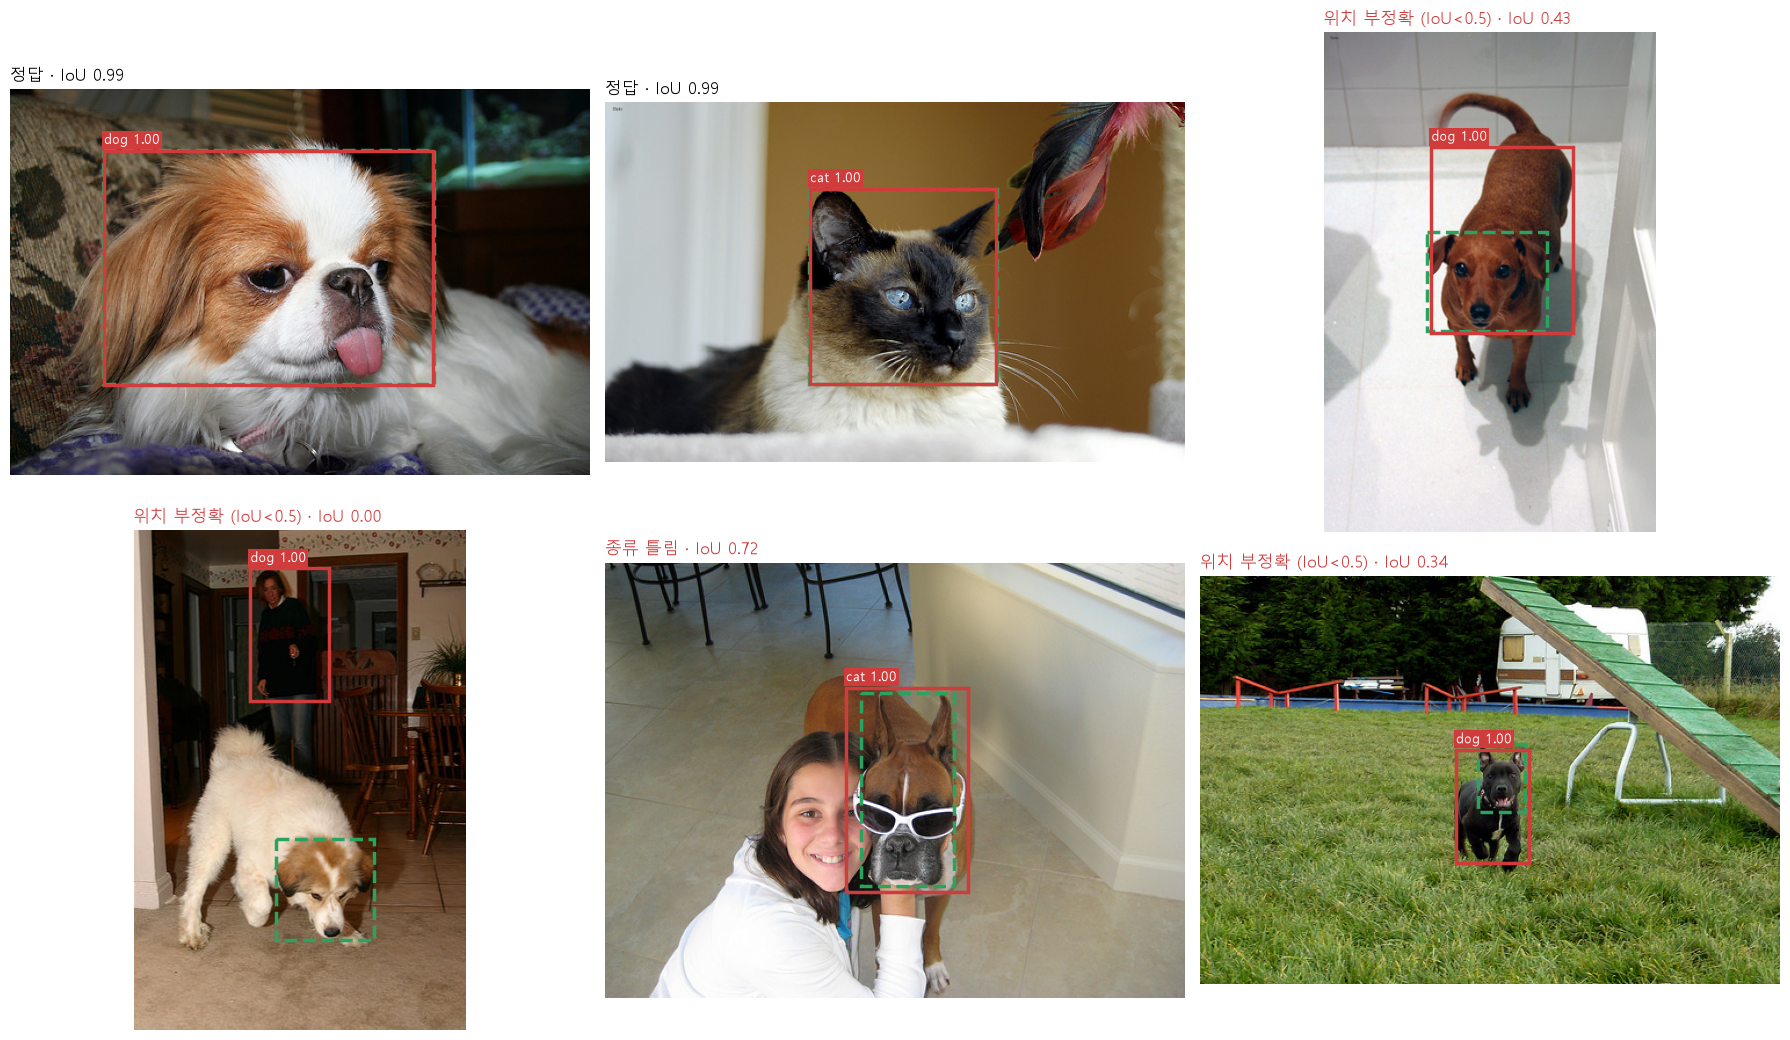

In [12]:
# 이미지별 판정
preds, gts = test_preds[best_name]  # 3-4에서 고른 최종 모델만 분석하기 위해
rows = []  # 이미지별 판정을 모으기 위해
for i, (pred, gt) in enumerate(zip(preds, gts)):
    gt_label, gt_box = int(gt["labels"][0]), gt["boxes"][0].tolist()  # 이미지당 정답이 거의 1개라 첫 정답과 비교하기 위해
    if len(pred["scores"]) == 0:
        rows.append({"i": i, "유형": "예측 없음", "IoU": 0.0, "점수": 0.0})  # 아무것도 못 찾은 경우도 기록하기 위해
        continue
    top = int(pred["scores"].argmax())  # 모델이 가장 확신한 예측을 보기 위해
    pred_label, pred_box = int(pred["labels"][top]), pred["boxes"][top].tolist()  # 정답과 비교하기 위해
    iou = box_iou(pred_box, gt_box)  # 위치가 맞았는지 판정하기 위해
    if pred_label != gt_label:
        kind = "종류 틀림"  # cat ↔ dog 혼동을 따로 세기 위해
    elif iou < 0.5:
        kind = "위치 부정확 (IoU<0.5)"  # 종류는 맞지만 박스가 어긋난 경우를 세기 위해
    else:
        kind = "정답"  # 종류 · 위치가 모두 맞은 경우를 세기 위해
    rows.append({"i": i, "유형": kind, "IoU": iou, "점수": float(pred["scores"][top])})  # 유형별 집계 · 사례 선택을 위해
diag = pd.DataFrame(rows)  # 집계 · 정렬을 위해 표로
print(f"{best_name} 판정:", diag["유형"].value_counts().to_dict(), f"· 평균 IoU {diag['IoU'].mean():.3f}")  # 오류 규모를 확인하기 위해

# 정답 2장 + 오류 4장 시각화
picks = pd.concat([diag[diag["유형"] == "정답"].nlargest(2, "IoU"), diag[diag["유형"] != "정답"].nlargest(4, "점수")])  # 잘 맞힌 예와 확신이 컸던 오류를 함께 보기 위해
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))  # 6장을 한 번에 비교하기 위해
for ax, (_, row) in zip(axes.ravel(), picks.iterrows()):
    image, target = loaders["test"].dataset[int(row["i"])]  # 정답 박스와 함께 보기 위해
    ax.imshow(image.permute(1, 2, 0))  # matplotlib 형식(높이, 너비, 채널)으로 바꾸기 위해
    x1, y1, x2, y2 = target["boxes"][0].tolist()  # 정답 박스를 그리기 위해
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="#2ca25f", linewidth=2.5, linestyle="--"))  # 예측과 구분되도록 정답은 초록 점선
    pred = preds[int(row["i"])]  # 같은 이미지의 예측을 꺼내기 위해
    if len(pred["scores"]):
        top = int(pred["scores"].argmax())  # 판정에 쓴 예측과 같은 박스를 그리기 위해
        x1, y1, x2, y2 = pred["boxes"][top].tolist()  # 예측 박스를 그리기 위해
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="#d03b3b", linewidth=2.5))  # 정답과 구분되도록 예측은 빨강
        ax.text(x1, y1 - 6, f"{CLASSES[int(pred['labels'][top])]} {float(pred['scores'][top]):.2f}", color="white",
                fontsize=10, bbox=dict(facecolor="#d03b3b", edgecolor="none", pad=1.5))  # 예측 클래스 · 점수를 보이기 위해
    ax.set_title(f"{row['유형']} · IoU {row['IoU']:.2f}", loc="left", color="black" if row["유형"] == "정답" else "#d03b3b")  # 오류가 눈에 띄도록 빨간 제목
    ax.axis("off")  # 사진만 보이도록 축 제거
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
정답 540 / 551장 (98.0%)                : 얼굴 위치 · 종류 모두 맞음
위치 부정확 6장 · 종류 틀림 5장         : 평균 IoU 0.880
얼굴 대신 몸 전체 (IoU 0.43 · 0.34)     : 작게 찍히거나 정면을 향한 강아지, 얼굴과 몸 털 색이 같아 경계가 흐린 사진
사람을 dog로 (IoU 0.00)                 : 학습 박스는 반려동물 얼굴뿐 → 함께 찍힌 사람의 머리 · 상체를 강아지로 착각
선글라스 쓴 강아지를 cat으로 (IoU 0.72) : 위치는 맞혔지만 소품 때문에 종류 혼동
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| box_iou() | 사용자 정의 함수 | 예측 · 정답 IoU | `box_iou(pred_box, gt_box)` |
| DataFrame() · concat()<br>nlargest() · iterrows() | pandas | 판정 표 · 사례 합치기<br>상위 사례 · 행 순회 | `pd.concat([...])`<br>`.nlargest(4, "점수")` · `picks.iterrows()` |
| argmax() · tolist() · permute() | torch.Tensor | 최고 점수 위치 · 좌표 · 채널 순서 | `image.permute(1, 2, 0)` |
| imshow() · Rectangle · text()<br>ravel() | matplotlib · numpy | 이미지 · 박스 · 점수<br>2 × 3 칸을 한 줄로 | `patches.Rectangle(..., linestyle="--")`<br>`axes.ravel()` |
| enumerate() · zip() | Python 내장 함수 | 번호 붙여 순회 · 짝짓기 | `enumerate(zip(preds, gts))` |
| if · elif · else<br>조건 표현식 | Python 기본 문법 | 오류 유형 분기<br>오류는 빨간 제목 | `if pred_label != gt_label: ... elif iou < 0.5:`<br>`"black" if ... else "#d03b3b"` |

### 4-4. 정답 없는 공식 test 이미지

**한글 요약**

박스 정답이 없는 공식 test 이미지 4장에 최종 모델 적용. 점수 0.5 이상 박스만 표시해 **처음 보는 사진에서도 얼굴을 찾는지** 눈으로 확인.

**실행 흐름**

1. **입력**: 공식 test 목록 `test_official` · 최종 모델
2. **처리**: 재현 가능한 무작위 4장 선택 → 이미지별 예측 → 점수 0.5 이상 박스만 선택
3. **저장**: 없음
4. **출력**: 4장 예측 시각화

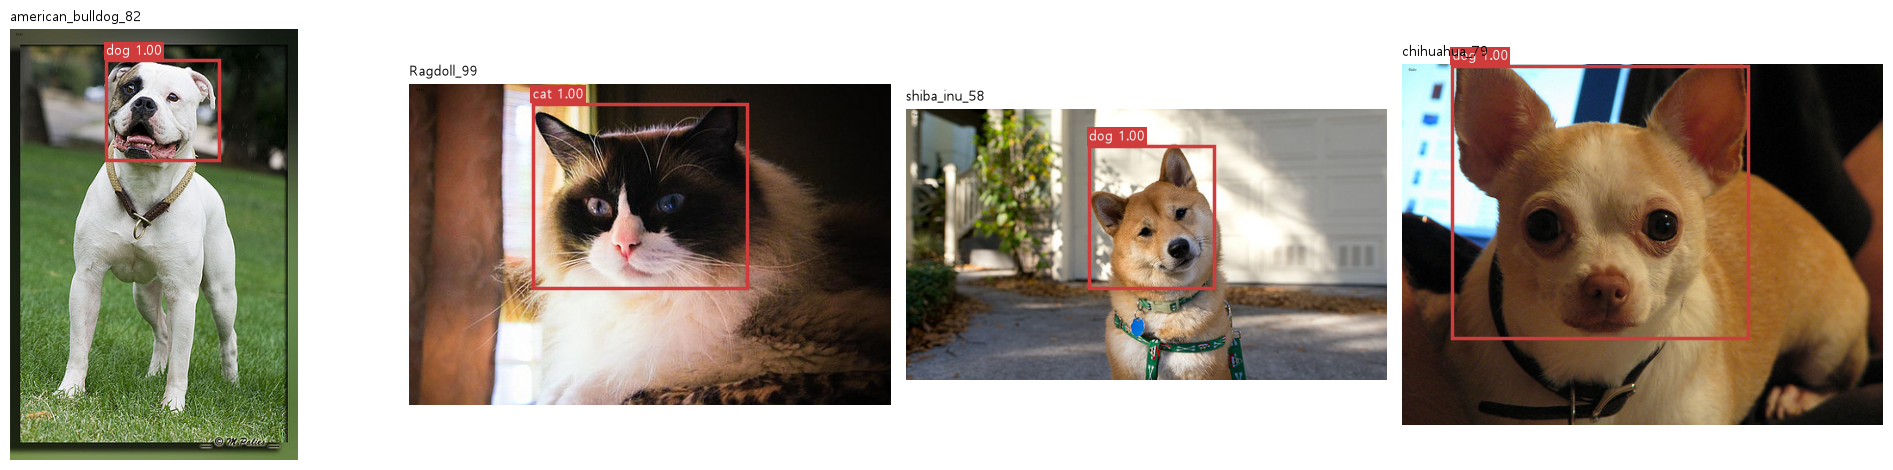

In [13]:
# 공식 test 예측
model = trained[best_name]  # 3-4에서 고른 최종 모델을 쓰기 위해
model.eval()  # 실제 추론 조건으로 예측하기 위해 평가 모드
names = test_official.sample(4, random_state=SEED)["image"].tolist()  # 다시 실행해도 같은 4장이 나오도록 시드 고정
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))  # 4장을 한 줄에 비교하기 위해
for ax, name in zip(axes, names):
    image = eval_tf(Image.open(img_dir / f"{name}.jpg").convert("RGB"))  # 평가와 같은 전처리를 쓰기 위해
    with torch.no_grad():
        pred = model([image.to(device)])[0]  # 메모리를 아끼기 위해 기울기 없이 1장 예측
    ax.imshow(image.permute(1, 2, 0))  # matplotlib 형식으로 바꾸기 위해
    for box, label, score in zip(pred["boxes"].cpu().tolist(), pred["labels"].cpu().tolist(), pred["scores"].cpu().tolist()):
        if score >= 0.5:  # 확신이 낮은 박스로 화면이 복잡해지지 않도록
            x1, y1, x2, y2 = box  # 박스를 그리기 위해 좌표 풀기
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="#d03b3b", linewidth=2.5))  # 예측 위치를 보이기 위해
            ax.text(x1, y1 - 6, f"{CLASSES[label]} {score:.2f}", color="white", fontsize=10,
                    bbox=dict(facecolor="#d03b3b", edgecolor="none", pad=1.5))  # 예측 클래스 · 점수를 보이기 위해
    ax.set_title(name, loc="left", fontsize=10)  # 어느 이미지인지 알기 위해
    ax.axis("off")  # 사진만 보이도록 축 제거
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
american_bulldog_82 · shiba_inu_58 · chihuahua_79 : dog, 점수 1.00, 얼굴 위치에 박스
Ragdoll_99                                        : cat, 점수 1.00, 얼굴 위치에 박스
정성적 확인                                       : 정답이 없어 수치 평가는 하지 않음, 처음 보는 사진에도 일반화되는지 눈으로 확인
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| sample() · tolist() | pandas | 재현 가능한 무작위 4장 | `test_official.sample(4, random_state=SEED)` |
| no_grad() | torch | 예측 시 기울기 끄기 | `with torch.no_grad():` |
| imshow() · Rectangle · text() | matplotlib | 이미지 · 박스 · 점수 | `ax.imshow(...)` · `ax.text(...)` |
| zip() | Python 내장 함수 | 박스 · 클래스 · 점수 짝 | `zip(pred["boxes"]..., pred["scores"]...)` |
| with · if | Python 기본 문법 | 블록 안에서만 기울기 끄기 · 0.5 이상만 | `with torch.no_grad():` · `if score >= 0.5:` |

---
## 5. 마무리

### 최종 결과

| 항목 | 결과 |
| :-- | :-- |
| **최종 모델** | SSDLite320-MobileNetV3 (COCO 사전학습, 3클래스 분류 헤드 교체, AdamW 40 epoch, 검증 기준 선택) |
| **비교용 개발 평가셋** (551장, 사후 확인 성능) | mAP@[.5:.95] **0.786** · mAP@50 **0.990** · mAP@75 **0.925** |
| **효율** | 파라미터 2.2M · 추론 244장/초 (SSD300 대비 1/11 크기, 2.4배 속도) |
| **이미지 단위 정답률** | 540 / 551장 (98.0%), 평균 IoU 0.880 |

### 핵심 결과

- **데이터부터 확인해야 평가 가능**: 공식 test에 박스 정답이 없음을 먼저 확인 → 정답 있는 3,671장으로 분할 재설계
- **기본 코드의 두 문제를 수치로 확인 · 수정**: 속성만 바꾸면 예측층 그대로(364 → 364) → 헤드 새로 생성 / 놓친 얼굴이 빠지는 평가 → COCO 방식
- **사전학습 모델은 위치를 금방 찾고, 학습은 경계를 다듬음**: mAP@50은 초반 0.95 이상, mAP@[.5:.95]는 내내 상승
- **정확도가 같다면 효율로 선택**: 검증 mAP 차이 0.0038 → 1/11 크기인 SSDLite 선택, 개발 평가셋에서도 같은 수준(0.786 vs 0.779)에 2.4배 속도

### 재현성 확인

같은 코드 · 같은 시드로 두 번 학습해 비교. 데이터 점검 · 분할 결과는 완전히 같고, 학습 결과는 GPU 연산의 비결정성 때문에 소수점 셋째 자리 수준에서 차이. 시드를 고정해도 GPU · 라이브러리 버전이 다르면 비트 단위로 같은 결과는 보장되지 않음. 결론(최종 모델 · 성능 수준 · 오류 유형)은 같음.

| 지표 (개발 평가셋) | 1차 실행 | 2차 실행 (이 노트북) |
| :-- | :-- | :-- |
| SSD300 mAP@[.5:.95] | 0.7765 | 0.7794 |
| SSDLite mAP@[.5:.95] | 0.7837 | 0.7856 |
| SSDLite 이미지 단위 정답 | 538 / 551 | 540 / 551 |

> 2차 실행 뒤 경고 처리 방식을 바꿈: `warnings`로 모든 경고를 숨기던 줄을 지우고, torchmetrics가 권장하는 `warn_on_many_detections = False`로 '이미지당 상위 100개만 평가' 안내만 끔. 계산에는 영향이 없고, 바꾼 코드로 축소 실행(학습 64장 · 1 epoch)해 출력되는 경고가 없음을 확인.

> 최종 모델 선택 위치도 바꿈: 처음 실행본은 4-1에서 평가 데이터 mAP로 최종 모델을 골랐음. 현재 실행 순서에서 평가 계산이 선택에 쓰이지 않도록 선택 코드를 3-4(검증 mAP · 모델 크기 기준)로 옮김. 다만 이 규칙도 평가 결과를 본 뒤 정했으므로 551장은 독립 최종 시험셋이 아닌 **비교용 개발 평가셋**으로 표기. 이 코드는 출력이 없고, 저장된 검증 mAP와 파라미터 수로 계산하면 같은 SSDLite가 선택되므로 저장된 출력은 그대로 유효 (전체 재실행은 하지 않음).

### 다음 단계

- **SSD300 학습 연장**: 15 epoch에서 아직 상승 중 → 같은 epoch 수로 다시 비교
- **배경 이미지 추가**: 사람 · 배경만 있는 이미지(박스 없는 음성 샘플)로 사람 오탐 감소
- **독립 최종 성능 확인**: 손대지 않은 새 홀드아웃이나 외부 데이터에서 최종 모델을 한 번만 평가
- **작은 얼굴 대응**: 입력 해상도 확대(SSD512 등) 또는 2단계 탐지기(Faster R-CNN)와 비교

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 데이터 점검** | XML 보유 · 중복 · 박스 분포 | 공식 test 정답 0장, 중복은 목록 밖 복사본 |
| **2. 분할 · 증강** | 품종 비율 유지 70 : 15 : 15, 박스 함께 변환 | 세 데이터 cat 비율 32% 안팎 |
| **3. 모델 학습** | 헤드 교체 확인, 최고 epoch 복원 | 출력 채널 364 → 12 |
| **4. 평가** | COCO mAP · 속도 · 오류 사례 (개발 평가셋) | SSDLite 0.786 · 244장/초 · 540/551 |
| **5. 마무리** | 검증 기준 · 효율로 모델 선택 | 검증 차이 0.0038, 1/11 크기 |